Universidad del Valle de Guatemala  
Departamento de Ciencias de la Computación  
CC2017 Modelación y Simulación

# 05. Estrategias, sensibilidad y validación

En este notebook se usa el modelo integrado para comparar cuatro decisiones contra no hacer cambios. Cada estrategia se evalúa con 500 escenarios de Monte Carlo, con la demanda esperada y con ventas 30 % menores. Todas usan las mismas semillas, por lo que las diferencias se deben a la estrategia y no al azar.

## 1. Estrategias

Los costos y efectos de cada estrategia son supuestos.

In [1]:
import sys
from dataclasses import replace

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append("../src")
from business_sim.montecarlo import run_montecarlo
from business_sim.params import BusinessParams, CustomerParams, QueueParams
from business_sim.queue_des import loss_table
from business_sim.strategies import STRATEGIES, apply_strategy

p, cp, qp = BusinessParams(), CustomerParams(), QueueParams()
tabla = loss_table(qp, list(range(0, 201, 10)), [1, 2, 3, 4], days=60, seed=5)
N = 500
pd.Series(STRATEGIES).to_frame("Cambio en los parámetros")

,Cambio en los parámetros
Sin cambios,Parámetros base.
Publicidad,Q3 000 al mes en publicidad y coeficiente de i...
Lealtad,Abandono promedio 25 % menor a cambio de 5 % d...
Contratar,Un empleado más que atiende en mostrador (un s...
Recortar fijos,Alquiler 20 % menor y servicios 10 % menores.


## 2. Comparación

In [2]:
resultados = {}
for nivel, etiqueta in [(1.0, "Demanda esperada"), (0.7, "Ventas 30 % menores")]:
    for nombre in STRATEGIES:
        r, _ = run_montecarlo(N, *apply_strategy(nombre, p, cp, qp), tabla, seed=1, level=nivel)
        resultados[(etiqueta, nombre)] = r

filas = []
for (etiqueta, nombre), r in resultados.items():
    filas.append({
        "Escenario": etiqueta, "Estrategia": nombre,
        "Probabilidad de llegar al mes 24": r["survived"].mean(),
        "Meses que aguanta (mediana)": r["months"].median(),
        "Caja final P10 (Q)": r["final_cash"].quantile(0.1),
        "Caja final P50 (Q)": r["final_cash"].quantile(0.5),
        "Caja final P90 (Q)": r["final_cash"].quantile(0.9),
        "Pérdida en cola": r["mean_loss"].mean(),
    })
comparacion = pd.DataFrame(filas).set_index(["Escenario", "Estrategia"])
comparacion.round(3)

Probabilidad de llegar al mes 24  \
Escenario           Estrategia                                         
Demanda esperada    Sin cambios                                0.672   
                    Publicidad                                 0.626   
                    Lealtad                                    0.634   
                    Contratar                                  0.318   
                    Recortar fijos                             0.826   
Ventas 30 % menores Sin cambios                                0.094   
                    Publicidad                                 0.070   
                    Lealtad                                    0.072   
                    Contratar                                  0.018   
                    Recortar fijos                             0.182   

                                    Meses que aguanta (mediana)  \
Escenario           Estrategia                                    
Demanda esperada    Sin cambios                            24.0   
                    Publicidad                             24.0   
                    Lealtad                                24.0   
                    Contratar                               5.0   
                    Recortar fijos                         24.0   
Ventas 30 % menores Sin cambios                             4.0   
                    Publicidad                              4.0   
                    Lealtad                                 4.0   
                    Contratar                               3.0   
                    Recortar fijos                          5.0   

                                    Caja final P10 (Q)  Caja final P50 (Q)  \
Escenario           Estrategia                                               
Demanda esperada    Sin cambios             -46733.516          136501.751   
                    Publicidad              -51213.236          150972.218   
                    Lealtad                 -31540.470          149699.654   
                    Contratar              -130125.017           79507.035   
                    Recortar fijos            3666.484          186901.751   
Ventas 30 % menores Sin cambios            -231486.979          -87053.371   
                    Publicidad             -241365.186          -97937.765   
                    Lealtad                -216304.328          -74821.201   
                    Contratar              -333781.593         -175651.841   
                    Recortar fijos         -181086.979          -36653.371   

                                    Caja final P90 (Q)  Pérdida en cola  
Escenario           Estrategia                                           
Demanda esperada    Sin cambios             356711.130            0.018  
                    Publicidad              389572.349            0.021  
                    Lealtad                 372907.061            0.021  
                    Contratar               341727.739            0.002  
                    Recortar fijos          407111.130            0.018  
Ventas 30 % menores Sin cambios              80813.467            0.010  
                    Publicidad               78225.750            0.012  
                    Lealtad                  89785.333            0.012  
                    Contratar                 9643.776            0.001  
                    Recortar fijos          131213.467            0.010

Con la demanda esperada y sin cambios el negocio llega al mes 24 en el 67.2 % de los escenarios. Recortar fijos sube esa probabilidad a 82.6 % y es la única estrategia con caja final positiva en el percentil 10 (Q3 666). Publicidad y lealtad suben la caja final mediana a Q150 972 y Q149 700, pero bajan la probabilidad de llegar al mes 24 a 62.6 % y 63.4 %. Contratar baja la pérdida en cola de 1.8 % a 0.2 %, pero la probabilidad cae a 31.8 %.

Con ventas 30 % menores ninguna estrategia evita el riesgo. Sin cambios el negocio llega al mes 24 en el 9.4 % de los escenarios y con recorte de fijos en el 18.2 %.

## 3. Recomendación

Se recomienda la estrategia con mayor probabilidad de llegar al mes 24 y, en caso de empate, la de mayor caja final mediana.

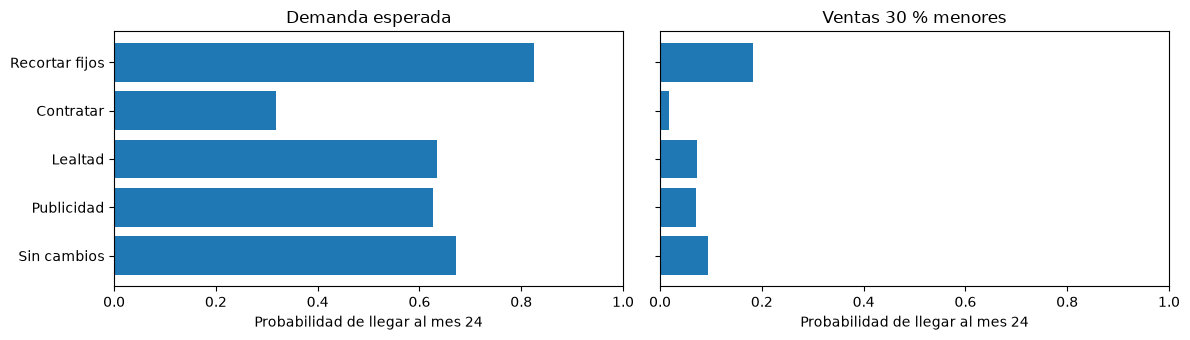

Demanda esperada: recomendación = Recortar fijos
Ventas 30 % menores: recomendación = Recortar fijos


In [3]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 3.5), sharey=True)
for eje, etiqueta in zip(ejes, ["Demanda esperada", "Ventas 30 % menores"]):
    datos = comparacion.loc[etiqueta, "Probabilidad de llegar al mes 24"]
    eje.barh(datos.index, datos.values)
    eje.set_xlim(0, 1)
    eje.set_title(etiqueta)
    eje.set_xlabel("Probabilidad de llegar al mes 24")
plt.tight_layout()
plt.show()

for etiqueta in ["Demanda esperada", "Ventas 30 % menores"]:
    t = comparacion.loc[etiqueta]
    mejor = t.sort_values(["Probabilidad de llegar al mes 24", "Caja final P50 (Q)"], ascending=False).index[0]
    print(f"{etiqueta}: recomendación = {mejor}")

En ambos escenarios se recomienda recortar costos fijos. Publicidad y lealtad mejoran el resultado mediano, pero sus costos llegan antes que sus beneficios y aumentan el riesgo de quedarse sin caja en los primeros meses. Contratar no se justifica porque la pérdida en cola ya es baja con 2 servidores.

## 4. Análisis de sensibilidad

Se cambia un parámetro a la vez en 20 % hacia abajo y hacia arriba, con 300 escenarios cada vez. El gráfico muestra cuánto cambia la probabilidad de llegar al mes 24.

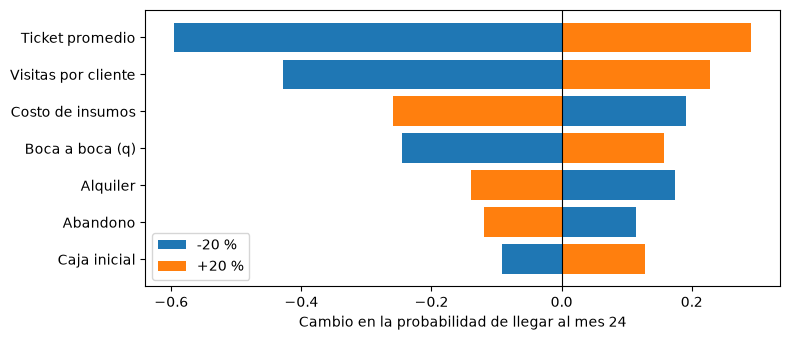

Probabilidad base = 0.672


,-20 %,+20 %,Rango
Parámetro,,,
Caja inicial,0.580,0.800,0.220
Abandono,0.787,0.553,0.233
Alquiler,0.847,0.533,0.313
Boca a boca (q),0.427,0.830,0.403
Costo de insumos,0.863,0.413,0.450
Visitas por cliente,0.243,0.900,0.657
Ticket promedio,0.077,0.963,0.887


In [4]:
cambios = {
    "Caja inicial": ("p", "initial_cash"),
    "Ticket promedio": ("p", "avg_ticket"),
    "Costo de insumos": ("p", "unit_cost"),
    "Alquiler": ("p", "rent"),
    "Boca a boca (q)": ("cp", "imitation"),
    "Abandono": ("cp", "mean_churn"),
    "Visitas por cliente": ("cp", "mean_visits"),
}
base_prob = resultados[("Demanda esperada", "Sin cambios")]["survived"].mean()
filas = []
for nombre, (grupo, campo) in cambios.items():
    fila = {"Parámetro": nombre}
    for f, col in [(0.8, "-20 %"), (1.2, "+20 %")]:
        pp, cc = p, cp
        if grupo == "p":
            pp = replace(p, **{campo: getattr(p, campo) * f})
        else:
            cc = replace(cp, **{campo: getattr(cp, campo) * f})
        fila[col] = run_montecarlo(300, pp, cc, qp, tabla, seed=1)[0]["survived"].mean()
    filas.append(fila)
sens = pd.DataFrame(filas).set_index("Parámetro")
sens["Rango"] = (sens["+20 %"] - sens["-20 %"]).abs()
sens = sens.sort_values("Rango")

plt.figure(figsize=(8, 3.5))
plt.barh(sens.index, sens["-20 %"] - base_prob, label="-20 %")
plt.barh(sens.index, sens["+20 %"] - base_prob, label="+20 %")
plt.axvline(0, color="black", lw=0.8)
plt.xlabel("Cambio en la probabilidad de llegar al mes 24")
plt.legend()
plt.tight_layout()
plt.show()
print(f"Probabilidad base = {base_prob:.3f}")
sens.round(3)

El ticket promedio es el parámetro más influyente. Con 20 % menos la probabilidad baja de 0.672 a 0.077, y con 20 % más sube a 0.963. Le siguen las visitas por cliente y el costo de insumos. La caja inicial es el parámetro menos influyente de los siete, con un rango de 0.220.

## 5. Validación contra datos publicados

Se compara la fracción de escenarios que se quedan sin caja antes del mes 12 con dos referencias. Según el Bureau of Labor Statistics de EE. UU., cerca de 20 % de los establecimientos nuevos no sobrevive su primer año. Parsa et al. (2005) reportan un cierre de 26 % en el primer año para restaurantes de Columbus, Ohio.

In [5]:
r = resultados[("Demanda esperada", "Sin cambios")]
cierre_12 = (r["months"] < 12).mean()
cierre_24 = (~r["survived"]).mean()
print(f"Escenarios del modelo sin caja antes del mes 24 = {cierre_24:.3f}")
pd.DataFrame({
    "Cierre en el primer año": [cierre_12, 0.20, 0.26],
    "Fuente": ["Modelo (500 escenarios)", "BLS, establecimientos de EE. UU.", "Parsa et al. (2005), restaurantes"],
}).set_index("Fuente").round(3)

Escenarios del modelo sin caja antes del mes 24 = 0.328


,Cierre en el primer año
Fuente,
Modelo (500 escenarios),0.328
"BLS, establecimientos de EE. UU.",0.200
"Parsa et al. (2005), restaurantes",0.260


En el modelo el 32.8 % de los escenarios se queda sin caja antes del mes 12, y la misma fracción antes del mes 24. Todos los cierres ocurren en el primer año. El valor es mayor que el 20 % del BLS y que el 26 % de Parsa et al. (2005), por lo que el modelo es algo más pesimista que esas referencias, aunque del mismo orden. Las referencias miden cierres reales en EE. UU. y el modelo mide quedarse sin caja, que no siempre implica cerrar.

## Conclusión

Con los supuestos de la cafetería tipo el riesgo de quedarse sin caja se concentra en el primer año. La decisión que más lo reduce es recortar costos fijos. Las estrategias que buscan más clientes rinden a largo plazo, pero solo convienen si hay caja para sostener sus costos iniciales. El ticket promedio y las visitas por cliente son los datos que más conviene estimar con cuidado.

## Referencias

- U.S. Bureau of Labor Statistics (2024). 34.7 percent of business establishments born in 2013 were still operating in 2023. *The Economics Daily*. https://www.bls.gov/opub/ted/2024/34-7-percent-of-business-establishments-born-in-2013-were-still-operating-in-2023.htm
- Parsa, H. G., Self, J. T., Njite, D. y King, T. (2005). Why restaurants fail. *Cornell Hotel and Restaurant Administration Quarterly*, 46(3), 304-322. https://doi.org/10.1177/0010880405275598